In [1]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

profile_df = pd.read_csv("../../data/processed/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)
profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,0.0,5.286957,2.0,-0.475000,0.251724,0.328571,1.000000,0.0,0.0,0.408284
1,10002013,1,0,0,0,0,0,0,0,0,...,0.0,4.634783,0.5,0.025000,0.389655,0.714286,0.000000,0.0,0.0,0.375000
2,10002155,1,0,0,0,0,0,0,0,0,...,0.0,5.661538,10.5,0.125000,0.341379,0.500000,0.000000,0.8,1.3,0.386760
3,10004457,0,0,0,1,0,0,0,0,0,...,0.0,0.000000,0.0,-0.075000,0.396552,0.357143,1.228571,0.0,0.0,0.333333
4,10007058,1,0,0,0,0,0,0,0,0,...,0.0,4.582609,1.5,-0.315789,0.220000,1.416667,0.742857,0.0,0.0,0.375000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4379,19998596,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4380,19998597,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4381,19998598,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4382,19998599,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000


In [2]:
# Correlation analysis
profile_df['subject_id'] = profile_df['subject_id'].astype(str)

# Select only numerical columns from the patient profile
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num = profile_df[numeric_cols]

# Print feature pairs with correlation higher than 0.7
corr_matrix = profile_num.corr().abs()
high_corr_var = np.where(corr_matrix > 0.7)
high_corr_var = [
    (corr_matrix.columns[x], corr_matrix.columns[y])
    for x, y in zip(*high_corr_var)
    if x != y and x < y
]
high_corr_var

[('unique_microorganisms_count', 'unique_antibiotics_count')]

In [3]:
# Drop highly correlated features
profile_df = profile_df.drop(columns=['unique_antibiotics_count'])

# Identify categorical columns to exclude
categorical_cols = [
    'subject_id', 'gender',
    'ACS_acute_ischemic', 'Chronic_ischemic',
    'Heart_failure', 'Valvular_nonrheumatic',
    'Myocarditis_or_cardiomyopathy',
    'Pericardial_disease', 'Endocarditis',
    'Cardiac_arrest',
    'Arrhythmias_or_conduction'
]

# Select only numerical columns for clustering
numeric_cols = [col for col in profile_df.columns if col not in categorical_cols]
numeric_df = profile_df[numeric_cols]

# Verify selected numerical columns
print("Numerical columns used for clustering:")
print(numeric_cols)
print(f"\nNumber of features: {len(numeric_cols)}")


Numerical columns used for clustering:
['number_of_hadm', 'age', 'lab_event_count', 'microbio_test_count', 'unique_microorganisms_count', 'unique_procedures_count', 'max_glucose', 'max_potassium', 'max_sodium', 'max_creatinine', 'max_bicarbonate', 'max_calcium, total', 'max_urea nitrogen', 'max_troponin t', 'max_ntprobnp', 'max_ptt', 'max_inr(pt)', 'max_hemoglobin', 'max_platelet count', 'max_white blood cells', 'max_cholesterol ratio (total/hdl)', 'min_ph', 'max_pco2', 'abnormal_lab_event_ratio']

Number of features: 24


Prior to clustering, duplicated patient profiles were removed. Only numerical variables were retained, while categorical and label-related features were excluded to avoid introducing artificial separation.

Highly correlated variables (absolute Pearson correlation > 0.7) were inspected, and `unique_antibiotics_count` was removed to reduce redundancy and potential dominance effects in distance computation.

All remaining numerical features were standardized using z-score normalization, as required by distance-based clustering algorithms such as K-means.


In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(numeric_df)


/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/utils/kneed.py:156: YellowbrickWarning: No 'knee' or 'elbow point' detected This could be due to bad clustering, no actual clusters being formed etc.
  warnings.warn(warning_message, YellowbrickWarning)
/Users/sararialiti/miniconda3/envs/DA4DH/lib/python3.13/site-packages/yellowbrick/cluster/elbow.py:374: YellowbrickWarning: No 'knee' or 'elbow' point detected, pass `locate_elbow=False` to remove the warning
  warnings.warn(warning_message, YellowbrickWarning)


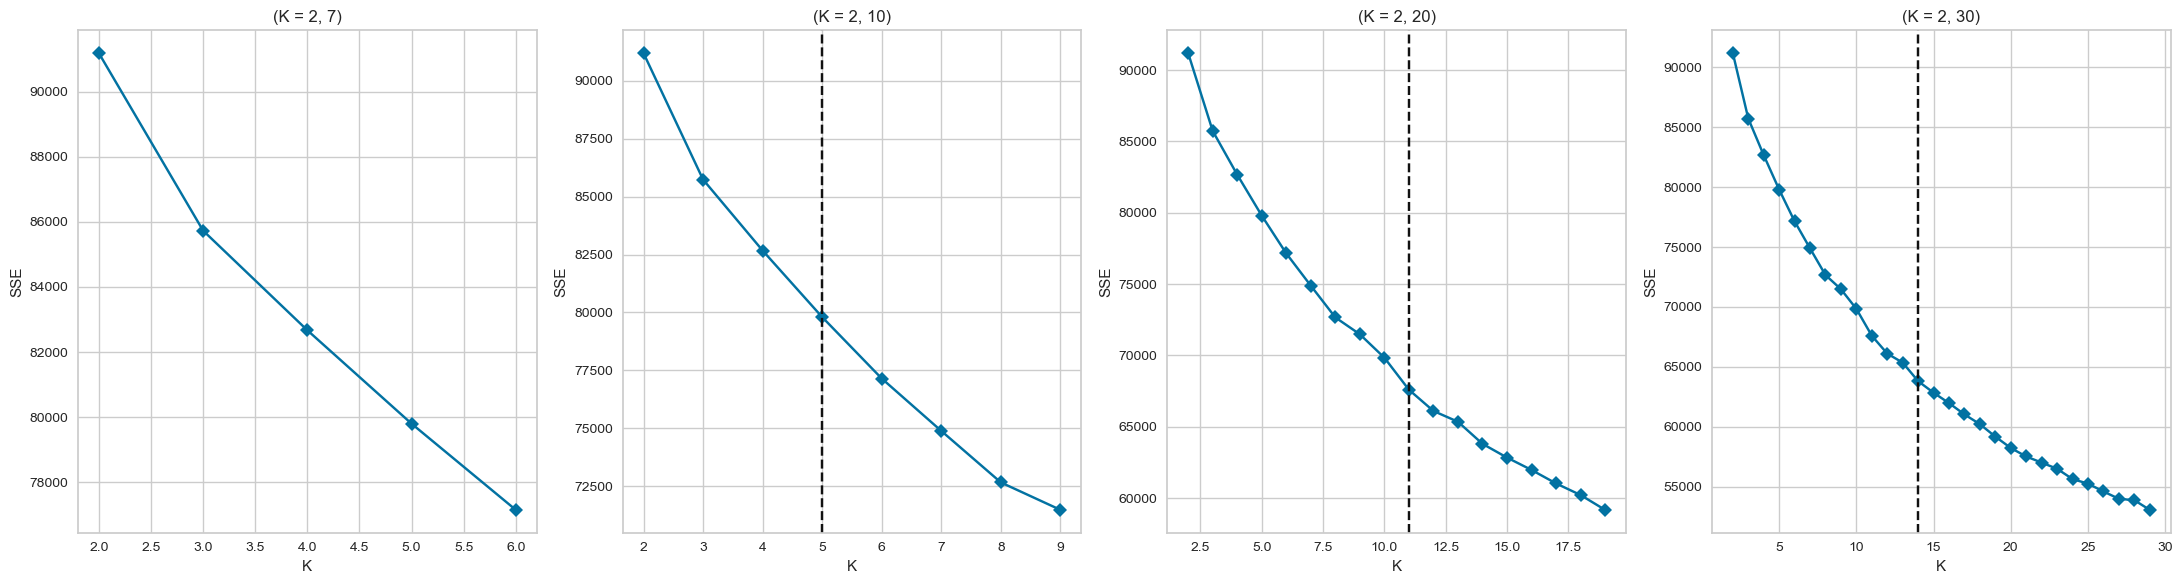

K suggested by the elbow method: [np.int64(5), np.int64(11), np.int64(14)]


In [5]:
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

random_state = 42  # fixed random state for reproducibility
# Multiple ranges to test
k_start = 2
k_max_list = [7, 10, 20, 30]

model = KMeans(n_init=10, max_iter=500, random_state=random_state)

fig, axs = plt.subplots(1, len(k_max_list), figsize=(22, 6))

best_Ks = []

for i, k_max in enumerate(k_max_list):
    
    visualizer = KElbowVisualizer(
        model,
        k=(k_start, k_max),
        metric='distortion',    # SSE (inertia)
        timings=False,
        ax=axs[i]
    )

    visualizer.fit(X)  
    
    axs[i].set_title(f'(K = {k_start}, {k_max})')
    axs[i].set_ylabel('SSE')
    axs[i].set_xlabel('K')
    
    elbow_k = visualizer.elbow_value_
    elbow_score = visualizer.elbow_score_

    if elbow_k is not None and elbow_k not in best_Ks:
        best_Ks.append(elbow_k)

plt.tight_layout()
plt.show()
plt.style.use("default") 

print("K suggested by the elbow method:", best_Ks)


In [6]:
# Loop to evaluate clustering metrics for k from 2 to 10
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn import metrics

results = []

# Evaluate k from 2 to 11
for k in range(2, 12):
    kmeans = KMeans(n_clusters=k, n_init=10, max_iter=500, random_state=random_state)
    kmeans.fit(X)
    labels = kmeans.labels_
    
    sse = kmeans.inertia_
    silhouette = silhouette_score(X, labels)
    db = metrics.davies_bouldin_score(X, labels)
    
    results.append([k, sse, silhouette, db])

results_df = pd.DataFrame(results, columns=["K", "SSE", "Silhouette", "DB_score"])
print(results_df)


    K           SSE  Silhouette  DB_score
0   2  91184.626447    0.276810  2.286898
1   3  85731.440606    0.103678  2.648835
2   4  82669.659562    0.078952  2.438472
3   5  79798.938384    0.055718  2.700494
4   6  77150.137456    0.058152  2.569204
5   7  74889.253385    0.064076  2.486888
6   8  72667.858369    0.065433  2.310066
7   9  71484.993056    0.061089  2.382790
8  10  69843.087944    0.062777  2.292029
9  11  67599.714980    0.068350  2.143808


The number of clusters was selected by combining multiple internal validation criteria.  
The Sum of Squared Errors (SSE), analyzed through the elbow method across different ranges of *k*, decreases monotonically without exhibiting a clear elbow beyond very small values of *k*.

To complement this analysis, internal validation metrics were computed for *k* ranging from 2 to 11. The silhouette score shows a clear maximum at **k = 2** (≈ 0.28), while rapidly decreasing for larger values of *k*. The Davies–Bouldin index gradually decreases for larger values of K, reflecting its known tendency to favor finer partitions.

Overall, these results indicate that **k = 2** provides the most meaningful partition according to internal clustering validity criteria.


The sharp decline in silhouette values for *k* > 2 suggests that the data do not naturally organize into multiple well-separated groups, but rather follow a continuous structure. In this setting, increasing *k* mainly forces artificial subdivisions of an underlying continuum, a known limitation of K-means when applied to gradually varying data.


In [7]:
from sklearn.metrics import adjusted_rand_score

labels_runs = []
for seed in range(10):
    km = KMeans(n_clusters=2, n_init=1, random_state=seed)
    labels_runs.append(km.fit_predict(X))

ari = []
for i in range(len(labels_runs)):
    for j in range(i+1, len(labels_runs)):
        ari.append(adjusted_rand_score(labels_runs[i], labels_runs[j]))

np.mean(ari), np.std(ari)


(np.float64(0.9755824209602767), np.float64(0.019235232275883644))

Since K-means is sensitive to centroid initialization, the robustness of the solution for *k = 2* was assessed by repeating the clustering with different random seeds.

The agreement between solutions was quantified using the Adjusted Rand Index (ARI). Across 10 runs, the mean ARI was approximately **0.98**, with a very small standard deviation, indicating an almost identical partition in all cases. This confirms that the solution is highly stable and not driven by random initialization effects.


/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_60354/1111866711.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=unique_values, y=value_counts, palette="tab10")


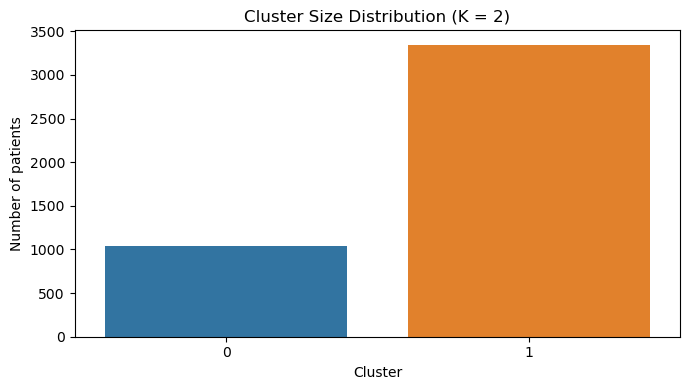

Cluster 0: 1041 patients
Cluster 1: 3343 patients


In [8]:
from sklearn.cluster import KMeans

k = 2
kmeans = KMeans(n_clusters=k, n_init=10, max_iter=500, random_state=random_state)
kmeans.fit(X)

labels = kmeans.labels_

np.unique(labels, return_counts=True)

# Distribution of patients across clusters
unique_values, value_counts = np.unique(labels, return_counts=True)

plt.figure(figsize=(7, 4))
sns.barplot(x=unique_values, y=value_counts, palette="tab10")

plt.xlabel("Cluster")
plt.ylabel("Number of patients")
plt.title("Cluster Size Distribution (K = 2)")
plt.tight_layout()
plt.show()

# Print cluster sizes
for c, n in zip(unique_values, value_counts):
    print(f"Cluster {c}: {n} patients")


In [9]:
# Centroids
centroids_scaled = pd.DataFrame(kmeans.cluster_centers_, columns=numeric_df.columns)
centroids_scaled.index.name = "cluster"
display(centroids_scaled)


,number_of_hadm,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_procedures_count,max_glucose,max_potassium,max_sodium,max_creatinine,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.541912,0.141929,1.079180,0.929392,0.656283,0.507072,0.852255,0.912937,0.353405,0.832679,...,0.337626,0.591000,0.622892,-0.302436,0.424314,0.576956,-0.070385,-0.453564,0.806775,0.892957
1,-0.168750,-0.044196,-0.336054,-0.289410,-0.204365,-0.157901,-0.265390,-0.284286,-0.110049,-0.259294,...,-0.105136,-0.184036,-0.193967,0.094178,-0.132130,-0.179662,0.021918,0.141238,-0.251227,-0.278064


In [10]:
# Attach cluster labels to the original profile dataframe
assert len(labels) == len(profile_df) == len(numeric_df)

dfc = profile_df.copy()
dfc["cluster"] = labels


In [11]:
# Compute cluster means and medians
means = dfc.groupby("cluster")[numeric_df.columns].mean()
medians = dfc.groupby("cluster")[numeric_df.columns].median()

print("Cluster means:")
display(means)

print("Cluster medians:")
display(medians)


Cluster means:


,number_of_hadm,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_procedures_count,max_glucose,max_potassium,max_sodium,max_creatinine,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio
cluster,,,,,,,,,,,,,,,,,,,,,
0,1.310279,71.434198,338.614793,2.721422,0.591739,4.839577,5.518892,1.068861,0.745037,3.717442,...,7.935769,5.187724,7.311239,-0.306352,0.543747,1.558280,0.175765,-0.236119,1.059462,0.504069
1,1.043972,69.677834,90.285073,0.737661,0.079569,2.690099,2.380472,0.620016,0.604073,1.163625,...,1.126233,2.415155,2.474200,-0.117521,0.331815,0.760601,0.219452,0.046605,0.114089,0.325794


Cluster medians:


,number_of_hadm,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_procedures_count,max_glucose,max_potassium,max_sodium,max_creatinine,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio
cluster,,,,,,,,,,,,,,,,,,,,,
0,1.0,71.0,272.0,2.0,0.0,4.0,4.433333,1.000000,0.750000,2.428571,...,0.0,4.521739,3.5,-0.315789,0.455172,1.285714,0.0,0.0,0.6,0.500000
1,1.0,69.0,74.0,0.0,0.0,2.0,1.866667,0.611111,0.666667,0.857143,...,0.0,0.853846,1.0,-0.050000,0.280000,0.657143,0.0,0.0,0.0,0.333333


Cluster centroids were analyzed both in standardized (z-score) space and in the original feature scale.  
Centroid values in z-score space represent deviations from the global dataset mean, while real-scale summaries provide clinically interpretable magnitudes.

**Cluster 0** exhibits a markedly more intensive clinical profile, characterized by higher volumes of laboratory and microbiological tests, a greater number of procedures, higher abnormal laboratory event ratios, and elevated maxima for several biochemical markers (e.g., glucose, creatinine, urea nitrogen, pCO₂). This pattern reflects increased diagnostic activity and laboratory alteration.

**Cluster 1** displays the opposite pattern, with lower test and procedure counts, lower abnormality ratios, and generally less extreme laboratory values, corresponding to a more standard and less intensive clinical profile.

Importantly, age and the number of hospital admissions show very similar distributions across clusters, indicating that the separation is not driven by demographic factors but by differences in clinical activity and laboratory patterns.


In [12]:
# Top features that distinguish each cluster
z = centroids_scaled.copy()

for c in z.index:
    top_pos = z.loc[c].sort_values(ascending=False).head(8)
    top_neg = z.loc[c].sort_values(ascending=True).head(8)
    print(f"\n=== Cluster {c} (n={np.sum(labels==c)}) ===")
    print("==Above the global mean:==")
    print(top_pos)
    print("==Below the global mean:==")
    print(top_neg)



=== Cluster 0 (n=1041) ===
==Above the global mean:==
lab_event_count             1.079180
max_urea nitrogen           1.066768
microbio_test_count         0.929392
max_potassium               0.912937
abnormal_lab_event_ratio    0.892957
max_glucose                 0.852255
max_creatinine              0.832679
max_pco2                    0.806775
Name: 0, dtype: float64
==Below the global mean:==
min_ph                              -0.453564
max_hemoglobin                      -0.302436
max_cholesterol ratio (total/hdl)   -0.070385
age                                  0.141929
max_troponin t                       0.319320
max_ntprobnp                         0.337626
max_sodium                           0.353405
max_calcium, total                   0.395999
Name: 0, dtype: float64

=== Cluster 1 (n=3343) ===
==Above the global mean:==
min_ph                               0.141238
max_hemoglobin                       0.094178
max_cholesterol ratio (total/hdl)    0.021918
age          

In [13]:
# Spread across clusters to identify the most discriminative features
# Features with the highest spread are those for which the cluster centroids are most separated
spread = centroids_scaled.max(axis=0) - centroids_scaled.min(axis=0)
display(spread.sort_values(ascending=False).head(15))


lab_event_count                1.415234
max_urea nitrogen              1.398956
microbio_test_count            1.218802
max_potassium                  1.197223
abnormal_lab_event_ratio       1.171021
max_glucose                    1.117645
max_creatinine                 1.091972
max_pco2                       1.058002
unique_microorganisms_count    0.860648
max_inr(pt)                    0.816858
max_bicarbonate                0.785430
max_ptt                        0.775035
max_white blood cells          0.756619
number_of_hadm                 0.710661
unique_procedures_count        0.664972
dtype: float64

To identify which variables most strongly separate the clusters, we computed the spread between centroid values, defined as the difference between the maximum and minimum centroid z-scores for each feature.

Features with a larger spread correspond to dimensions along which the cluster centroids are farther apart, and therefore contribute most to the overall separation achieved by K-means.


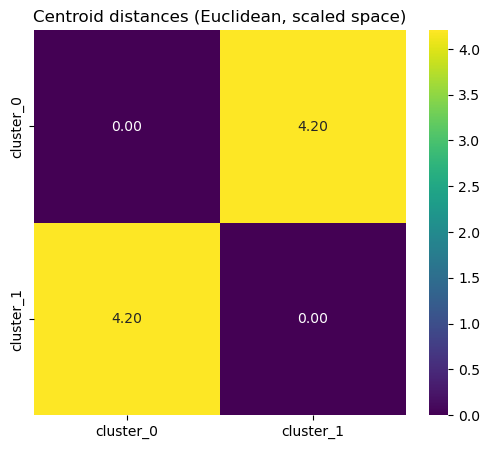

In [14]:
# Centroids in the space where KMeans was fitted (values in z-score space)
centers = pd.DataFrame(
    kmeans.cluster_centers_,
    index=[f"cluster_{i}" for i in range(kmeans.n_clusters)],
    columns=numeric_df.columns
)

C = centers.to_numpy()
dist_matrix = np.linalg.norm(C[:, None, :] - C[None, :, :], axis=2)


plt.figure(figsize=(6, 5))
sns.heatmap(
    dist_matrix,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    xticklabels=centers.index,
    yticklabels=centers.index
)
plt.title("Centroid distances (Euclidean, scaled space)")
plt.show()

# Interpretation:
# - Each cell (i, j) shows the distance between the centroids of clusters i and j in standardized space.
# - Larger values indicate more separated clusters (centroids farther apart).
# - Smaller values indicate more similar clusters (centroids closer together).


Pairwise Euclidean distances between cluster centroids were computed in the standardized feature space used by K-means. For *k = 2*, the distance between centroids is approximately **4.2**, indicating a substantial global separation across features.

This distance reflects an aggregate multivariate separation rather than sharp boundaries in individual dimensions, and is therefore consistent with the continuous structure observed in the data.


Primary feature pairs: [('age', 'lab_event_count'), ('age', 'microbio_test_count'), ('lab_event_count', 'unique_procedures_count'), ('max_glucose', 'abnormal_lab_event_ratio')]


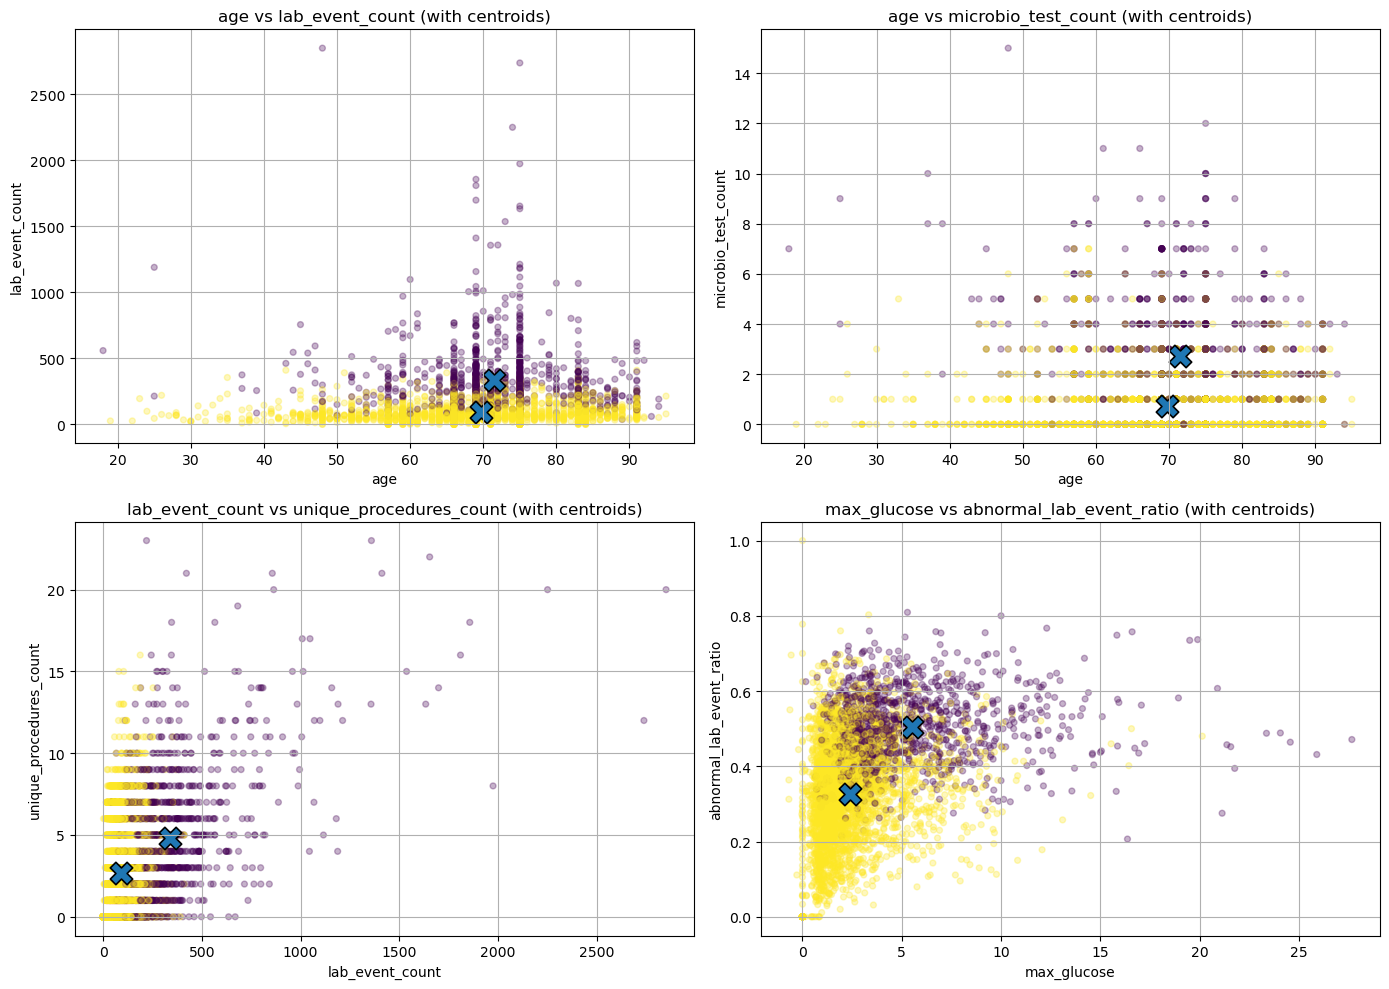

Secondary feature pairs: [('max_creatinine', 'max_urea nitrogen'), ('max_creatinine', 'max_potassium'), ('max_inr(pt)', 'max_ptt'), ('max_inr(pt)', 'max_platelet count')]


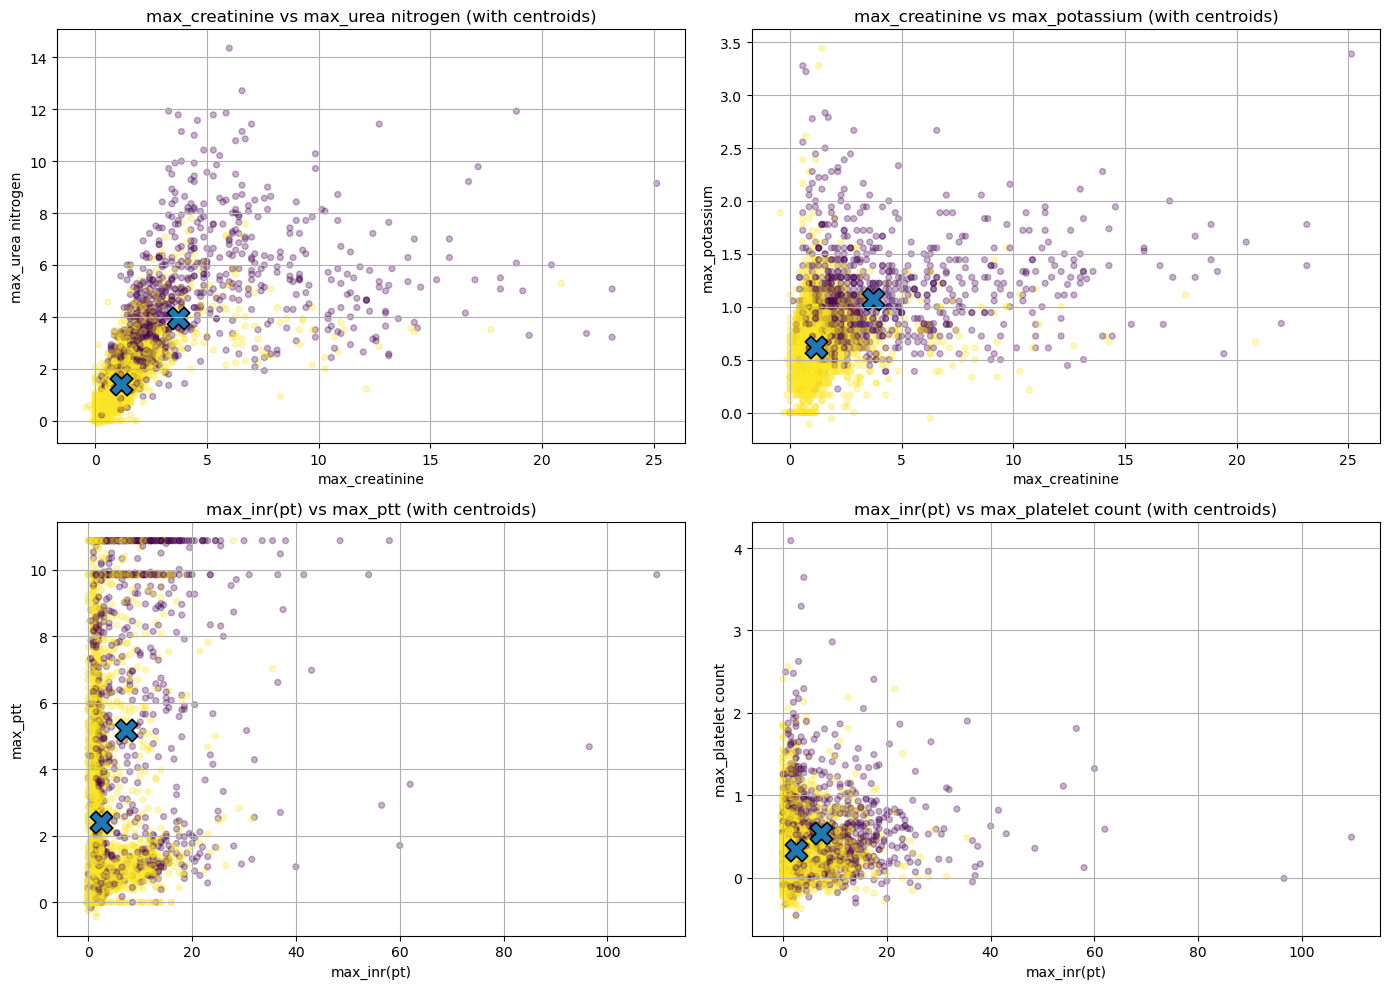

In [15]:
def scatter_with_centroids(
    ax,
    x_feature,
    y_feature,
    data,
    labels,
    kmeans,
    scaler,
    point_size=20,
    alpha=0.35,
    centroid_size=260
):
    xi = data.columns.get_loc(x_feature)
    yi = data.columns.get_loc(y_feature)

    x = data[x_feature].values
    y = data[y_feature].values

    centroids = kmeans.cluster_centers_
    cx = centroids[:, xi] * scaler.scale_[xi] + scaler.mean_[xi]
    cy = centroids[:, yi] * scaler.scale_[yi] + scaler.mean_[yi]

    ax.scatter(x, y, c=labels, s=point_size, alpha=alpha)
    ax.scatter(cx, cy, marker="X", s=centroid_size, edgecolor="black", linewidth=1.2)

    ax.set_xlabel(x_feature)
    ax.set_ylabel(y_feature)
    ax.grid(True)


def plot_feature_pairs(feature_pairs, title_prefix):
    feature_pairs = [
        (a, b) for a, b in feature_pairs
        if a in numeric_df.columns and b in numeric_df.columns
    ]

    print(f"{title_prefix} feature pairs:", feature_pairs)

    n = len(feature_pairs)
    cols = 2
    rows = int(np.ceil(n / cols))

    fig, axs = plt.subplots(rows, cols, figsize=(14, 5 * rows))
    axs = np.array(axs).reshape(-1)

    for idx, (x_feature, y_feature) in enumerate(feature_pairs):
        scatter_with_centroids(
            axs[idx],
            x_feature,
            y_feature,
            data=numeric_df,
            labels=labels,
            kmeans=kmeans,
            scaler=scaler,
            point_size=18,
            alpha=0.30,
            centroid_size=260
        )
        axs[idx].set_title(f"{x_feature} vs {y_feature} (with centroids)")

    for j in range(idx + 1, len(axs)):
        axs[j].axis("off")

    plt.tight_layout()
    plt.show()


primary_feature_pairs = [
    ("age", "lab_event_count"),
    ("age", "microbio_test_count"),
    ("lab_event_count", "unique_procedures_count"),
    ("max_glucose", "abnormal_lab_event_ratio"),
]

secondary_feature_pairs = [
    ("max_creatinine", "max_urea nitrogen"),
    ("max_creatinine", "max_potassium"),
    ("max_inr(pt)", "max_ptt"),
    ("max_inr(pt)", "max_platelet count"),
]


plot_feature_pairs(primary_feature_pairs, "Primary")
plot_feature_pairs(secondary_feature_pairs, "Secondary")



Primary feature triples: [('age', 'lab_event_count', 'microbio_test_count'), ('lab_event_count', 'unique_procedures_count', 'abnormal_lab_event_ratio'), ('max_glucose', 'abnormal_lab_event_ratio', 'lab_event_count')]


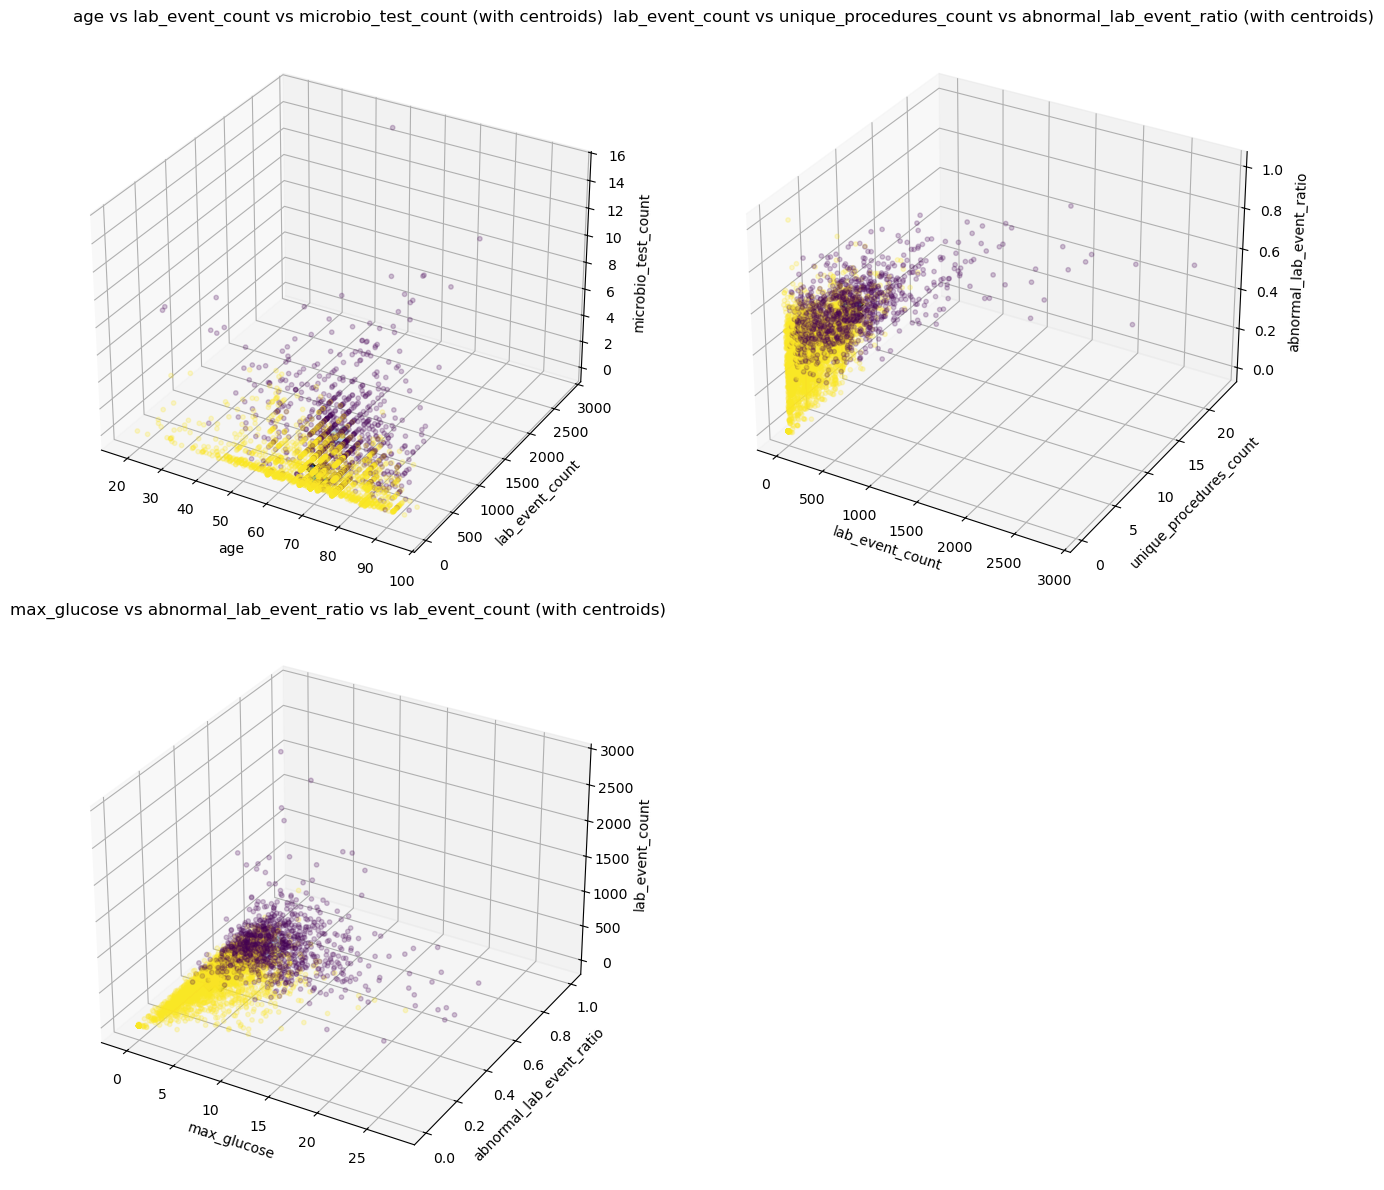

Secondary feature triples: [('max_creatinine', 'max_urea nitrogen', 'max_potassium'), ('max_inr(pt)', 'max_ptt', 'max_platelet count'), ('max_creatinine', 'max_potassium', 'abnormal_lab_event_ratio')]


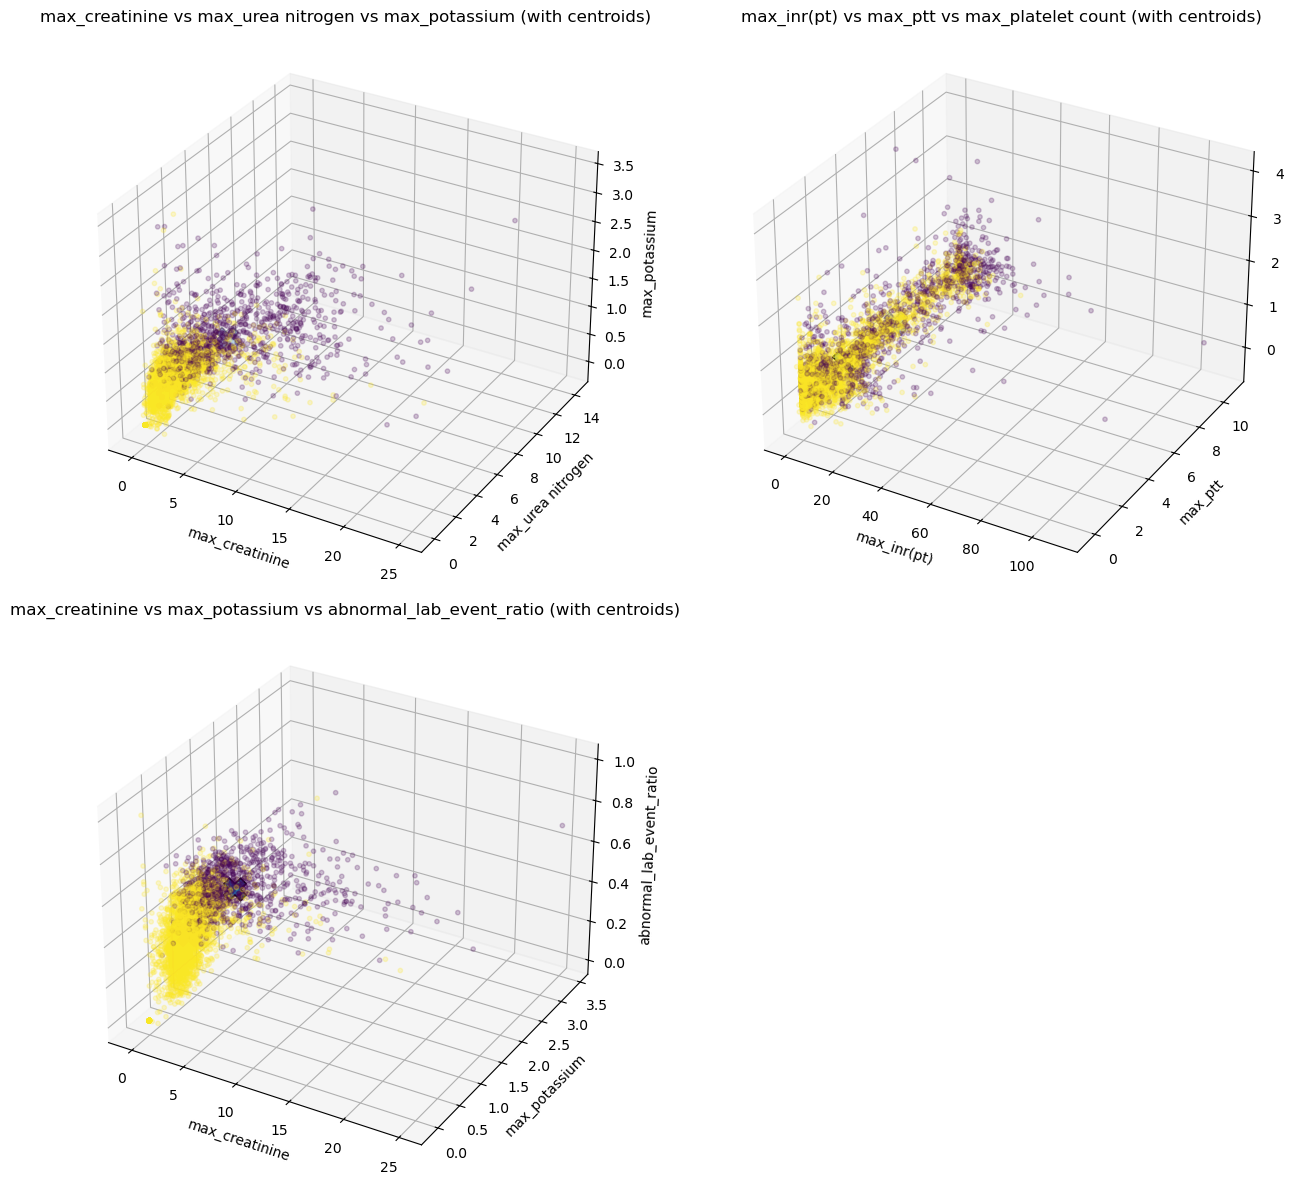

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D 


def scatter3d_with_centroids(
    ax,
    x_feature,
    y_feature,
    z_feature,
    data,
    labels,
    kmeans,
    scaler,
    point_size=12,
    alpha=0.25,
    centroid_size=260
):
    xi = data.columns.get_loc(x_feature)
    yi = data.columns.get_loc(y_feature)
    zi = data.columns.get_loc(z_feature)

    x = data[x_feature].values
    y = data[y_feature].values
    z = data[z_feature].values

    centroids = kmeans.cluster_centers_
    cx = centroids[:, xi] * scaler.scale_[xi] + scaler.mean_[xi]
    cy = centroids[:, yi] * scaler.scale_[yi] + scaler.mean_[yi]
    cz = centroids[:, zi] * scaler.scale_[zi] + scaler.mean_[zi]

    ax.scatter(x, y, z, c=labels, s=point_size, alpha=alpha)
    ax.scatter(
        cx, cy, cz,
        marker="X",
        s=centroid_size,
        edgecolor="black",
        linewidth=1.2
    )

    ax.set_xlabel(x_feature)
    ax.set_ylabel(y_feature)
    ax.set_zlabel(z_feature)
    ax.set_title(f"{x_feature} vs {y_feature} vs {z_feature} (with centroids)")
    ax.grid(True)


def plot_feature_triples(feature_triples, title_prefix):
    feature_triples = [
        (a, b, c) for a, b, c in feature_triples
        if a in numeric_df.columns
        and b in numeric_df.columns
        and c in numeric_df.columns
    ]

    print(f"{title_prefix} feature triples:", feature_triples)

    n = len(feature_triples)
    cols = 2
    rows = int(np.ceil(n / cols))

    fig = plt.figure(figsize=(14, 6 * rows))

    for i, (x_feature, y_feature, z_feature) in enumerate(feature_triples, start=1):
        ax = fig.add_subplot(rows, cols, i, projection="3d")
        scatter3d_with_centroids(
            ax,
            x_feature,
            y_feature,
            z_feature,
            data=numeric_df,
            labels=labels,
            kmeans=kmeans,
            scaler=scaler,
            point_size=10,
            alpha=0.22,
            centroid_size=260
        )

    for j in range(n + 1, rows * cols + 1):
        ax = fig.add_subplot(rows, cols, j, projection="3d")
        ax.set_axis_off()

    plt.tight_layout()
    plt.show()


primary_feature_triples = [
    ("age", "lab_event_count", "microbio_test_count"),
    ("lab_event_count", "unique_procedures_count", "abnormal_lab_event_ratio"),
    ("max_glucose", "abnormal_lab_event_ratio", "lab_event_count"),
]

secondary_feature_triples = [
    ("max_creatinine", "max_urea nitrogen", "max_potassium"),
    ("max_inr(pt)", "max_ptt", "max_platelet count"),
    ("max_creatinine", "max_potassium", "abnormal_lab_event_ratio"),
]


plot_feature_triples(primary_feature_triples, "Primary")
plot_feature_triples(secondary_feature_triples, "Secondary")


/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_60354/1381369360.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_60354/1381369360.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
/var/folders/6c/ryq330rs7bl7nmdhthbq78380000gn/T/ipykernel_60354/1381369360.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")


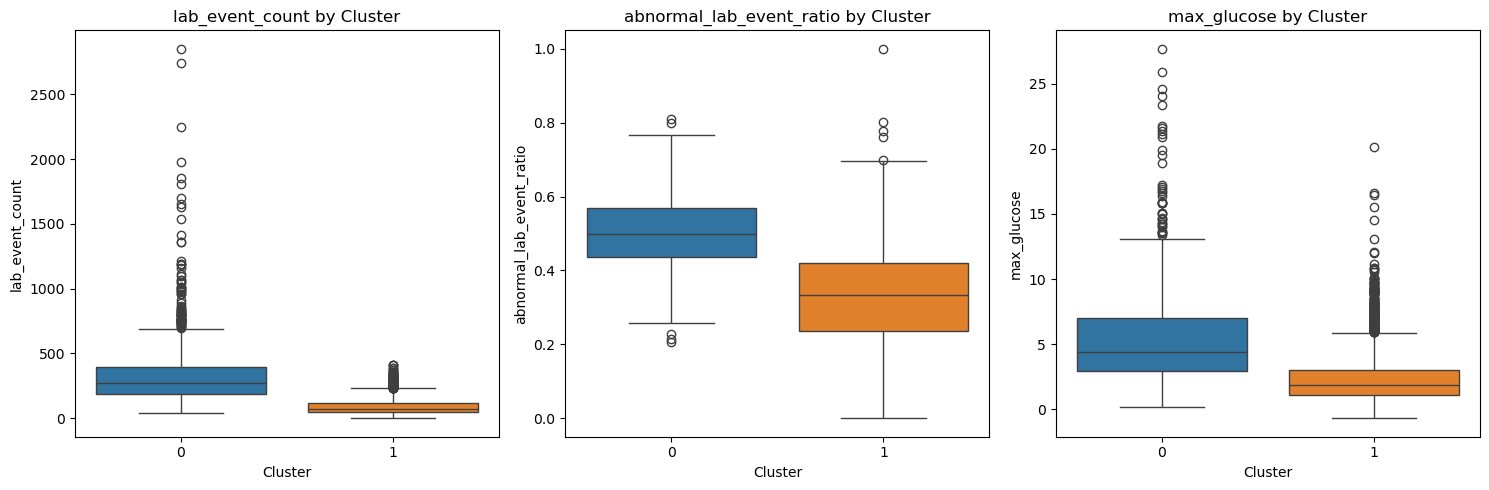

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a DataFrame with the original data and the assigned cluster
df_box = numeric_df.copy()
df_box["Cluster"] = labels

vars_to_plot = [
    "lab_event_count",
    "abnormal_lab_event_ratio",
    "max_glucose",
]

plt.figure(figsize=(15, 5))

for i, var in enumerate(vars_to_plot, 1):
    plt.subplot(1, len(vars_to_plot), i)
    sns.boxplot(x="Cluster", y=var, data=df_box, palette="tab10")
    plt.title(f"{var} by Cluster")
    plt.xlabel("Cluster")
    plt.ylabel(var)

plt.tight_layout()
plt.show()


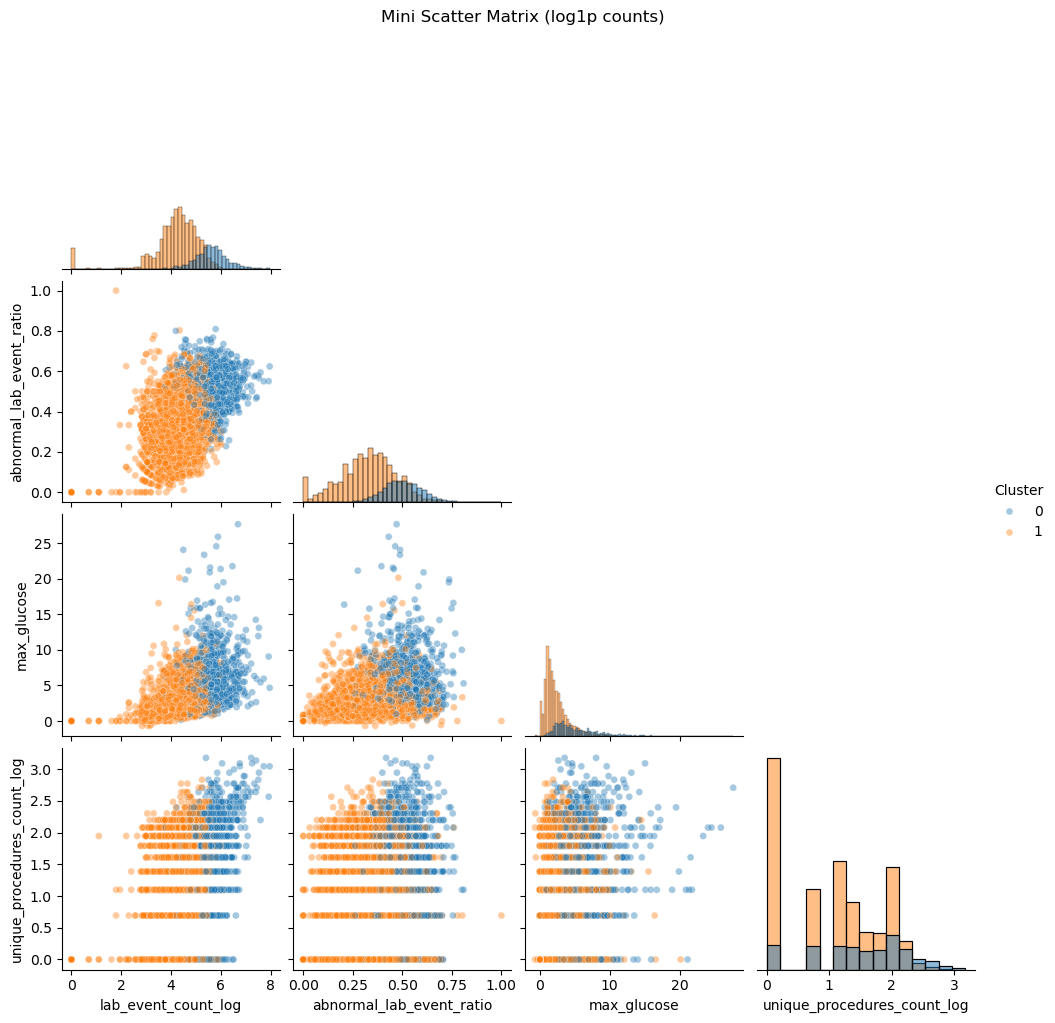

In [18]:
df_scatter = numeric_df.copy()
df_scatter["Cluster"] = labels

df_scatter["lab_event_count_log"] = np.log1p(df_scatter["lab_event_count"])
df_scatter["unique_procedures_count_log"] = np.log1p(df_scatter["unique_procedures_count"])

vars_scatter = [
    "lab_event_count_log",
    "abnormal_lab_event_ratio",
    "max_glucose",
    "unique_procedures_count_log"
]

sns.pairplot(
    df_scatter[vars_scatter + ["Cluster"]],
    hue="Cluster",
    palette="tab10",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.4, "s": 25}
)

plt.suptitle("Mini Scatter Matrix (log1p counts)", y=1.02)
plt.show()


Two-dimensional and three-dimensional projections, boxplots, and pairwise scatter plots consistently support the interpretation derived from centroid analysis. Across all visualizations, Cluster 0 occupies regions associated with higher laboratory activity, greater procedural intensity, and higher abnormality levels, while Cluster 1 is concentrated in lower-intensity regions.

Substantial overlap is observed in intermediate regions, and no sharp decision boundaries emerge. This confirms that the clustering captures a dominant gradient of clinical and laboratory intensity rather than discrete, well-isolated patient subgroups. No single variable alone explains the partition, highlighting the multivariate nature of the clustering structure.


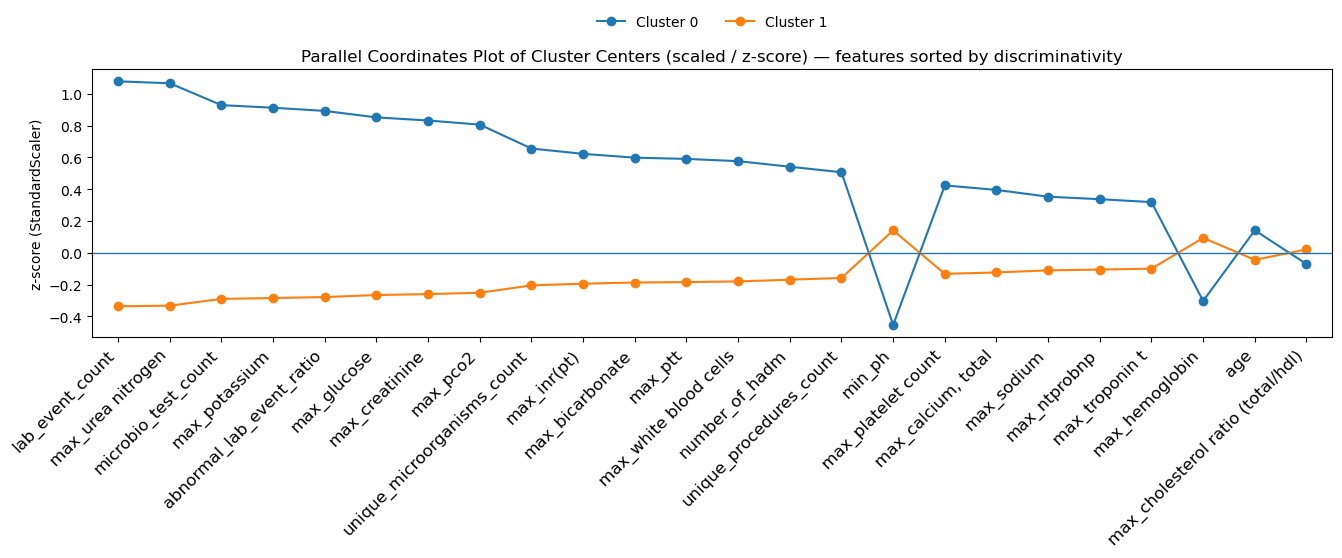

In [19]:
# Parallel Coordinates (centroids in z-score space) with features sorted by discriminativity

centers_scaled = kmeans.cluster_centers_   
cols = list(numeric_df.columns)

# Discriminativity = (max - min) across centroids for each feature (in z-score)
spread = centers_scaled.max(axis=0) - centers_scaled.min(axis=0)
order = np.argsort(-spread)  # descending

centers_ord = centers_scaled[:, order]
cols_ord = [cols[i] for i in order]

N = centers_ord.shape[1]
x = np.arange(N)

plt.figure(figsize=(16, 4))
for i in range(centers_ord.shape[0]):
    plt.plot(x, centers_ord[i], marker='o', label=f'Cluster {i}')

plt.axhline(0, linewidth=1)  # baseline: global mean
plt.xticks(x, cols_ord, fontsize=12, rotation=45, ha='right')
plt.xlim(-0.5, N - 0.5)
plt.ylabel("z-score (StandardScaler)")

plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.25),
           ncol=centers_ord.shape[0], frameon=False)

plt.subplots_adjust(top=0.78)
plt.title("Parallel Coordinates Plot of Cluster Centers (scaled / z-score) — features sorted by discriminativity")
plt.show()


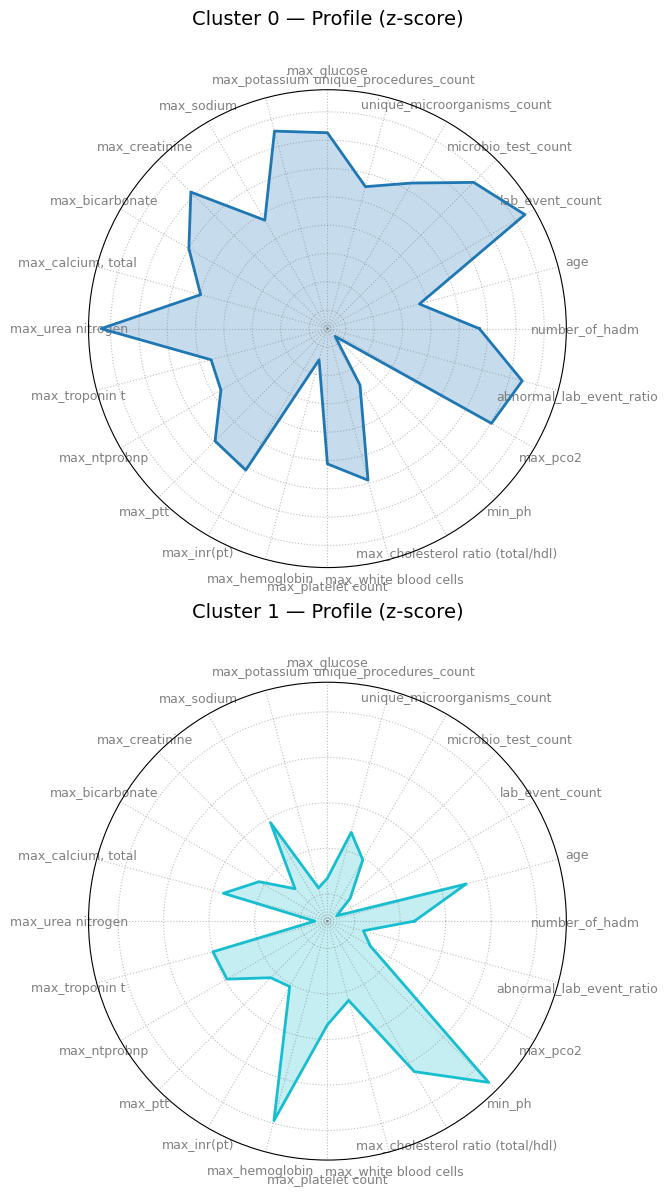

In [20]:
from math import pi
import numpy as np
import matplotlib.pyplot as plt

centers_np = kmeans.cluster_centers_  

N = centers_np.shape[1]
features_labels = numeric_df.columns.tolist()
colors = plt.cm.tab10(np.linspace(0, 1, centers_np.shape[0]))

plt.figure(figsize=(12, 12))

for cluster_id in range(centers_np.shape[0]):
    values = centers_np[cluster_id].tolist()
    values += values[:1]

    angles = [n / float(N) * 2*pi for n in range(N)]
    angles += angles[:1]

    ax = plt.subplot(centers_np.shape[0], 1, cluster_id + 1, polar=True)

    ax.plot(angles, values, linewidth=2, color=colors[cluster_id])
    ax.fill(angles, values, alpha=0.25, color=colors[cluster_id])

    plt.xticks(angles[:-1], features_labels, size=9, color="grey")
    ax.grid(color="grey", linestyle="dotted", alpha=0.5)
    ax.set_yticklabels([])
    ax.set_title(f"Cluster {cluster_id} — Profile (z-score)", size=14, y=1.12)

plt.tight_layout()
plt.show()


Parallel coordinates and radar plots provide a compact multidimensional summary of the cluster profiles in standardized space. A coherent pattern emerges across the most discriminative features, with Cluster 0 showing systematically positive deviations from the global mean and Cluster 1 showing negative deviations on the same dimensions.

These visual summaries confirm that the K-means solution is driven by a global shift across multiple activity- and laboratory-related variables, rather than by isolated effects.
